# 第13章 直方图处理（跟随代码）

> 《OpenCV轻松入门：面向Python》（李立宗）第 13 章跟随代码。**全量收录原书代码**（例 13.1~例 13.15 + 章内独立演示），缺失例题已按书补全，代码以网页笔记 docs/opencv/ch13.md 为准（含笔误与参数修正：`calcHist` 的 `ranges` 用 `[0, 256]`——原书 `[0, 255]` 会丢掉灰度值 255 的像素）。
> `cv2.imshow` / `cv_show` 需在**本地 Python 环境**运行（弹窗显示，Notebook 服务内看不到窗口）；运行前请确认**工作目录为素材根目录**（本文件夹，picture*.jpg/png 等素材都在这里），否则 `imread` 返回 None。
> 素材替换：原书 boat.jpg / boat.bmp / boatGray.bmp 用 picture1.jpg 顶替，girl.bmp、8.bmp 用 picture2.png 顶替，equ.bmp 用 picture12.jpg 顶替；掩模区域按素材图尺寸适配。

# 第十三章 直方图处理

> 直方图（histogram）统计图像内各灰度级出现的次数：横轴是灰度级，纵轴是该灰度级的像素个数。对比度差、过暗、过亮的图像，问题都写在直方图的形状里。全章例题：例 13.1~13.2（matplotlib.hist 绘制）、例 13.3~13.8（calcHist 统计 + plot 绘制）、例 13.9~13.10（掩模直方图）、例 13.11（均衡化）、例 13.12~13.15（subplot / imshow）。

In [ ]:
# cv_show 辅助函数：原书跟随代码沿用的显示封装（本地运行显示窗口用，弹窗显示后按任意键关闭）
import cv2

def cv_show(name, img):
    cv2.imshow(name, img)
    cv2.waitKey(0)
    cv2.destroyAllWindows()


## 13.2 绘制直方图

两条路线：`matplotlib.pyplot` 的 `hist()` 函数直接绘制（13.2.1，例 13.1~13.2）；`cv2.calcHist()` 先统计直方图数据、再用 `plot()` 画出来（13.2.2，例 13.3~13.8）；用掩模只统计感兴趣区域见 13.2.3（例 13.9~13.10）。

### 13.2.1 使用 Numpy 绘制直方图

`matplotlib.pyplot.hist(X, BINS)` 根据数据源和灰度级分组绘制直方图：

- **X**：数据源，必须是一维的。图像通常是二维的，要先用 `ravel()` 函数把图像按行顺序拉平成一维再作参数（`ravel()` 返回视图，`flatten()` 返回副本，直方图统计只读不写用 `ravel()` 更省内存）；
- **BINS**：灰度级分组的组数，如 256 个灰度级每 16 个一组划分成 16 个子集，BINS=16。

### 例 13.1 · 用 hist() 绘制直方图

`o.ravel()` 把三通道一起拉平，统计的是 B、G、R 全部像素值的混合分布；BINS 取 256，按全部灰度级分组。运行后同时弹出原始图像窗口（cv2.imshow）与直方图窗口（plt）。

In [ ]:
# ===== 13.2.1 例 13.1：matplotlib.hist 绘制直方图（原书 boat.jpg → picture1.jpg） =====
import cv2
import matplotlib.pyplot as plt

o = cv2.imread("picture1.jpg")     # 读入彩色图（原书 image\boat.jpg）
cv2.imshow("original", o)          # 显示原图
plt.hist(o.ravel(), 256)           # ravel 拉平成 1 维；按 256 个灰度级分组统计
cv2.waitKey()
cv2.destroyAllWindows()


### 例 13.2 · BINS=16 的分组直方图

把 [0, 255] 的 256 个灰度级划成 16 个子集，每根柱子对应一个 16 级宽的区间——同一个数据源，BINS 的值随分组变化。

In [ ]:
# ===== 13.2.1 例 13.2：BINS=16 的直方图（原书 boat.bmp → picture1.jpg） =====
import cv2
import matplotlib.pyplot as plt

o = cv2.imread("picture1.jpg")     # 原书 image\boat.bmp
plt.hist(o.ravel(), 16)            # 256 个灰度级划成 16 个子集，BINS=16


### 13.2.2 使用 OpenCV 绘制直方图

`cv2.calcHist()` 统计直方图信息，返回 shape 为 (256, 1) 的 ndarray（元素是各灰度级的像素个数），再用 `plot()` 把统计值画成直方曲线：

```text
hist = cv2.calcHist( images, channels, mask, histSize, ranges, accumulate )
```

写法要点：**images、channels、histSize 都要用方括号括起来**（`[img]`、`[0]`、`[256]`）；channels 的 [0]/[1]/[2] 对应 B/G/R 通道；mask 统计整幅图设 `None`；accumulate 是累计标识，默认 False，一般不设。

> **勘误（ranges 建议 [0, 256]）**：原书统一写 `ranges=[0, 255]`，实测会**丢掉灰度值 255 的像素**——histSize=256 时每个 bin 宽 255/256≈0.996，灰度值 255 落在最后一个 bin 之外被整体丢弃（实测 picture2.png 有 1039 个灰度 255 的像素凭空消失，直方图总和小于像素总数）。OpenCV 官方文档示例也是 `[0, 256]`，本章代码统一用 `[0, 256]`。

### 例 13.3 · calcHist 统计直方图信息

五个参数逐个给：`[img]` 原图、`[0]` 灰度图通道、`None` 不用掩模、`[256]` BINS、`[0, 256]` 统计范围。观察返回值：类型 ndarray、shape (256, 1)、size 256，前几条数据就是灰度级 0~5 各自的像素个数（原书打印全部 256 行）。

In [ ]:
# ===== 13.2.2 例 13.3：calcHist 统计直方图信息（原书 boat.jpg → picture1.jpg） =====
import cv2

img = cv2.imread("picture1.jpg", cv2.IMREAD_GRAYSCALE)    # 读灰度图（原书 image\boat.jpg）
hist = cv2.calcHist([img], [0], None, [256], [0, 256])    # 参数全部按写法要点给
print(type(hist))                  # 返回值类型
print(hist.shape)                  # 形状
print(hist.size)                   # 元素总数
print(hist[:6])                    # 前 6 个灰度级的统计值（原书打印全部 256 行）


**动手验证**（笔记补充）：用图 13.1 的 9 像素小数组（灰度级 1~5，出现次数 3、1、2、1、2）核对 `calcHist` 的计数逻辑——6 个 bin 的计数与手算逐 bin 一致。

In [ ]:
# ===== 13.2.2 动手验证：图 13.1 的小数组，calcHist 与手算对照 =====
import cv2
import numpy as np

img = np.array([[1, 1, 3],
                [2, 3, 5],
                [5, 1, 4]], np.uint8)               # 图 13.1 的 9 个像素
hist = cv2.calcHist([img], [0], None, [6], [0, 6])  # 6 个 bin：bin k 统计灰度值 k 的个数
print(hist.ravel())                                 # 各 bin 计数
hand = [0, 3, 1, 2, 1, 2]                           # 手算：1 出现 3 次、2 出现 1 次、3 出现 2 次、4 出现 1 次、5 出现 2 次
print((hist.ravel() == hand).all())                 # 逐 bin 比对


### 例 13.4 · plot 同时给定 x、y

`plt.plot(x, y)`：x 轴由 x = [0, 1, …, 6] 指定，y 轴由 y = [0.3, 0.4, 2, 5, 3, 4.5, 4] 指定。

In [ ]:
# ===== 13.2.2 例 13.4：plot 同时给 x 和 y =====
import matplotlib.pyplot as plt

x = [0, 1, 2, 3, 4, 5, 6]
y = [0.3, 0.4, 2, 5, 3, 4.5, 4]
plt.plot(x, y)                     # x 轴由 x 指定，y 轴由 y 指定


### 例 13.5 · plot 只给 y，x 自动补自然数序列

只给一个参数时，x 轴默认取自然数序列 [0, 1, …, n−1]，长度与 y 一致。画直方图正是利用这一点——calcHist 的返回值本身按灰度级 0~255 排列，只给 y，x 轴自然就是灰度级。

In [ ]:
# ===== 13.2.2 例 13.5：plot 只给 y，x 自动补自然数序列 =====
import matplotlib.pyplot as plt

y = [0.3, 0.4, 2, 5, 3, 4.5, 4]
plt.plot(y)                        # 只指定 y


### 例 13.6 · plot 两条曲线不同颜色

`color='r'` 把曲线设为红色、`color='g'` 设为绿色，两组数据画进同一窗口，按需要可换任意颜色。

In [ ]:
# ===== 13.2.2 例 13.6：plot 两条曲线不同颜色 =====
import matplotlib.pyplot as plt

a = [0.3, 0.4, 2, 5, 3, 4.5, 4]
b = [3, 5, 1, 2, 1, 5, 3]
plt.plot(a, color='r')             # color='r'：red，红色曲线
plt.plot(b, color='g')             # color='g'：green，绿色曲线


### 例 13.7 · plot 绘制 calcHist 的返回值

流程就两步：`calcHist` 出数据，`plot` 画数据——蓝色曲线即灰度图的直方图。

In [ ]:
# ===== 13.2.2 例 13.7：plot 绘制 calcHist 的返回值（原书 boatGray.bmp → picture1.jpg） =====
import cv2
import matplotlib.pyplot as plt

o = cv2.imread("picture1.jpg", cv2.IMREAD_GRAYSCALE)      # 灰度图（原书 image\boatGray.bmp）
histb = cv2.calcHist([o], [0], None, [256], [0, 256])     # 先统计
plt.plot(histb, color='b')                                # 再画成蓝色曲线
plt.show()


### 例 13.8 · 彩色图像三通道直方图

先分别统计 [0]、[1]、[2] 三个通道（即 B、G、R）的直方图数据，再依次画进同一窗口：三条曲线叠在一起，各通道的亮度分布差异一眼可见。

In [ ]:
# ===== 13.2.2 例 13.8：彩图三通道直方图（原书 girl.bmp → picture2.png） =====
import cv2
import matplotlib.pyplot as plt

o = cv2.imread("picture2.png")                            # 彩色图（原书 image\girl.bmp）
histb = cv2.calcHist([o], [0], None, [256], [0, 256])     # B 通道
histg = cv2.calcHist([o], [1], None, [256], [0, 256])     # G 通道
histr = cv2.calcHist([o], [2], None, [256], [0, 256])     # R 通道
plt.plot(histb, color='b')                                # 蓝色画 B
plt.plot(histg, color='g')                                # 绿色画 G
plt.plot(histr, color='r')                                # 红色画 R
plt.show()


### 13.2.3 使用掩模绘制直方图

`calcHist()` 的 mask 参数决定是否使用掩模图像（mask）：用了掩模，就只统计掩模指定区域的直方图。可以把掩模看成一块玻璃板——**白色（255）区域透明，黑色（0）区域不透明**，其本质是按位与：任意像素值与 255 按位与结果不变，与 0 按位与结果为 0。

构造方法两步：`np.zeros()` 生成全 0 数组，再把目标区域置 255。掩模必须与原始图像**大小相等**——用 `image.shape` 构造等大小的掩模最省心。

### 例 13.9 · 构造中心白色的掩模图像

600×600 全 0（全黑）二维数组，把第 200~399 行 × 第 200~399 列置 255，得到黑底中央一块 200×200 白方块的掩模图像。

In [ ]:
# ===== 13.2.3 例 13.9：构造中心白色的掩模图像 =====
import cv2
import numpy as np

mask = np.zeros([600, 600], np.uint8)   # 600×600 全 0（全黑）二维数组
mask[200:400, 200:400] = 255            # 第 200~399 行 × 第 200~399 列置 255（白）
cv2.imshow('mask', mask)
cv2.waitKey()
cv2.destroyAllWindows()


### 例 13.10 · 绘制掩模结果图像的直方图

整图直方图与掩模区域直方图画进同一窗口：上方的曲线是原始图像的（整体高），下方的是掩模区域的（整体矮）——后者只统计了 200×200 的小块。

自检性质：掩模直方图的 `sum()` 必须等于掩模白色区域的像素个数（40000），整图直方图的 `sum()` 必须等于图像总像素数（1442480）——总和对不上，多半是掩模尺寸、数据类型或 ranges 写法出了问题。

In [ ]:
# ===== 13.2.3 例 13.10：掩模直方图（原书 girl.bmp → picture2.png） =====
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("picture2.png", cv2.IMREAD_GRAYSCALE)   # 灰度图，1387×1040
mask = np.zeros(image.shape, np.uint8)                     # 与原图等大小的全 0 掩模
mask[200:400, 200:400] = 255                               # 白区：200 行 × 200 列（原书同款区域）

histImage = cv2.calcHist([image], [0], None, [256], [0, 256])   # 整图直方图
histMI = cv2.calcHist([image], [0], mask, [256], [0, 256])      # 掩模区域直方图
plt.plot(histImage)     # 整图曲线（整体高）
plt.plot(histMI)        # 掩模曲线（整体矮）
plt.show()

print(int(histImage.sum()), image.size)        # 总和核对
print(int(histMI.sum()), int((mask == 255).sum()))


## 13.3 直方图均衡化

直方图均衡化（histogram equalization）把挤在一起的灰度级摊开到整个灰度空间：算法两步——① 计算累计直方图；② 累计概率乘以目标空间的最大灰度级做区间转换（可留在原范围，也可扩展到 [0, 255]）。这种均衡是"统计概率 + 人眼视觉系统（HVS）"双重均衡：均衡化后的直方图不是处处等高，但按区间看各区间像素数大体一致（13.3.2，例 13.11）。

**拓展演示**（笔记补充）：自适应均衡化 CLAHE（本书未涉及）——普通均衡化对整幅图一刀切，噪声会被同步放大。OpenCV 另有限制对比度自适应直方图均衡化（CLAHE，Contrast Limited Adaptive Histogram Equalization）：把图像分块分别均衡，并限制每块直方图的高度，两行代码即可使用。

In [ ]:
# ===== 13.3.1 拓展：自适应均衡化 CLAHE（本书未涉及） =====
import cv2

img = cv2.imread('picture12.jpg', cv2.IMREAD_GRAYSCALE)       # 暗图，均衡化效果明显
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))   # 对比度限制 2.0，8×8 分块
res = clahe.apply(img)                                        # 对单通道图应用

cv2.imshow("original", img)
cv2.imshow("clahe", res)
cv2.waitKey()
cv2.destroyAllWindows()


### 例 13.11 · equalizeHist 直方图均衡化

picture12.jpg 是灰度均值约 57 的暗图（顶替原书 equ.bmp）：均衡化前整体偏暗，均衡化后亮度均衡、对比度增强。两个 matplotlib 窗口分别显示均衡化前后的直方图（matplotlib 默认字体不含中文，窗口标题会显示方框）。

均衡化后的直方图呈梳状尖峰属正常现象——大量像素被映射到相邻的少数灰度级上；人眼把相近灰度看成同一级，按区间看（如 [0,50]、[51,100]、… 五段）各段占比都在 0.2 附近，分布是均衡的。

> 注意：`equalizeHist` 只接受 **8 位单通道**图，对彩色图直接调用会报 `_src.type() == CV_8UC1` 断言错误；彩色图要拆成 B、G、R 三个通道分别均衡再合并（见下方补充演示）。

In [ ]:
# ===== 13.3.2 例 13.11：直方图均衡化（原书 equ.bmp → picture12.jpg） =====
import cv2
import matplotlib.pyplot as plt

# ----------读取原始图像----------
img = cv2.imread('picture12.jpg', cv2.IMREAD_GRAYSCALE)   # 暗图，灰度均值约 57（原书 equ.bmp）
# ----------直方图均衡化处理----------
equ = cv2.equalizeHist(img)                               # 一行完成均衡化
# ----------显示均衡化前后的图像----------
cv2.imshow("original", img)
cv2.imshow("result", equ)
# ----------显示均衡化前后的直方图----------
plt.figure("原始图像直方图")       # 构建窗口（matplotlib 默认字体不含中文，标题会显示方框）
plt.hist(img.ravel(), 256)         # 均衡化前的直方图
plt.figure("均衡化结果直方图")     # 构建新窗口
plt.hist(equ.ravel(), 256)         # 均衡化后的直方图
# ----------等待释放窗口----------
cv2.waitKey()
cv2.destroyAllWindows()


**补充演示**（跟随代码原有）：彩色图的均衡化——把 picture2.png 拆成 B、G、R 三个通道分别 `equalizeHist`，再 `merge` 回去（`cv_show` 弹窗对比均衡化前后的图像），并用两个 figure 窗口画出均衡化前后各通道的直方图。

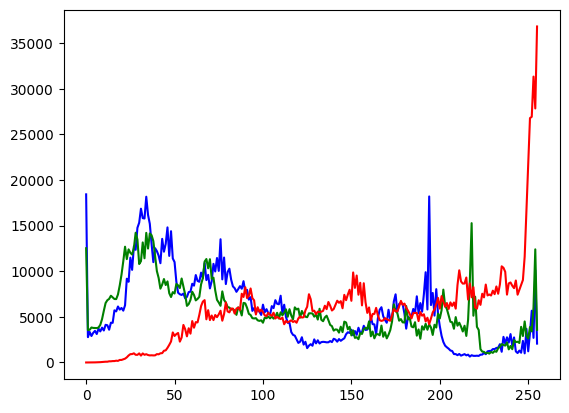

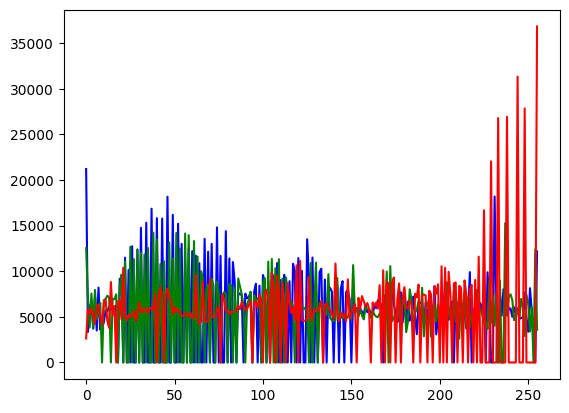

In [256]:
img=cv2.imread("picture2.png")

b,g,r=cv2.split(img)
equb=cv2.equalizeHist(b)
equg=cv2.equalizeHist(g)
equir=cv2.equalizeHist(r)

equ=cv2.merge([equb,equg,equir])

cv_show("equalized",equ)
cv_show("original",img)

plt.figure("原始图像直方图:")
histb=cv2.calcHist([b],[0],None,[256],[0,256])
histg=cv2.calcHist([g],[0],None,[256],[0,256])
histr=cv2.calcHist([r],[0],None,[256],[0,256])
plt.plot(histb,color='b')
plt.plot(histg,color='g')
plt.plot(histr,color='r')

plt.figure("均衡化后图像直方图:")
equhistb=cv2.calcHist([equb],[0],None,[256],[0,256])
equhistg=cv2.calcHist([equg],[0],None,[256],[0,256])
equhistr=cv2.calcHist([equir],[0],None,[256],[0,256])
plt.plot(equhistb,color='b')
plt.plot(equhistg,color='g')
plt.plot(equhistr,color='r')

plt.show()

## 13.4 pyplot 模块介绍

`matplotlib.pyplot` 模块提供了类似 MATLAB 的绘图框架，本章再用到其中两个函数：

- **subplot() 函数**：向当前窗口内添加一个子窗口对象，语法 `subplot(nrows, ncols, index)`。子窗口按**行方向**排序，序号从 **1** 开始；所有参数都小于 10 时可省略逗号写成 `subplot(234)` 紧凑形式（13.4.1，例 13.12）；
- **imshow() 函数**：显示图像，语法 `imshow(X, cmap=None)`，cmap 指定色彩空间。彩色图要先用 `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)` 把 BGR 转成 RGB 再显示；灰度图必须传二维数组并给 `cmap='gray'`，`_r` 后缀（reverse）黑白反转（13.4.2，例 13.13~13.15）。

### 例 13.12 · subplot 划分两个子窗口（13.4.1）

`plt.subplot(121)` / `plt.subplot(122)` 在 1 行 2 列的窗口网格里取第 1、第 2 个子窗口：左边画均衡化前的直方图，右边画均衡化后的直方图。实测序号写 0 会直接报错 `ValueError: num must be an integer with 1 <= num <= 1, not 0`——index 从 1 开始。

In [ ]:
# ===== 13.4.1 例 13.12：subplot 两个子窗口（原书 equ.bmp → picture12.jpg） =====
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('picture12.jpg', cv2.IMREAD_GRAYSCALE)   # 灰度图
equ = cv2.equalizeHist(img)                               # 均衡化
plt.figure("subplot 示例")
plt.subplot(121), plt.hist(img.ravel(), 256)              # 1 行 2 列的第 1 个子窗口：均衡化前
plt.subplot(122), plt.hist(equ.ravel(), 256)              # 第 2 个子窗口：均衡化后
plt.show()


### 13.4.2 imshow 函数

`matplotlib.pyplot.imshow(X, cmap=None)` 用来显示图像：X 是图像信息，cmap 是色彩空间（默认 RGB(A)）。OpenCV 的 imread 读出的是 BGR 顺序、灰度图是二维数组——与 imshow 的默认假设不配套，下面三个例子分别看彩色图、灰度图的不同显示形式。

### 例 13.13 · imshow 显示彩色图（BGR 转 RGB）

左图直接显示：cv2.imread 读到的图像是 BGR 模式，而 imshow 按 RGB 模式解释，通道顺序错乱、颜色不对；右图先经 `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)` 转成 RGB 再显示，正常。`plt.axis('off')` 表示关闭坐标轴的显示。

In [ ]:
# ===== 13.4.2 例 13.13：imshow 显示彩色图，BGR 要转 RGB（原书 girl.bmp → picture2.png） =====
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('picture2.png')                          # cv2.imread 读出的是 BGR 顺序
imgRGB = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)             # BGR → RGB
plt.figure("显示结果")
plt.subplot(121)
plt.imshow(img), plt.axis('off')      # 左：直接显示 BGR 图，通道错乱，颜色不对
plt.subplot(122)
plt.imshow(imgRGB), plt.axis('off')   # 右：转成 RGB 后显示正常
plt.show()


### 例 13.14 · imshow 显示灰度图的四种形式

四种形式中只有"灰度图像 + cmap=plt.cm.gray"（右下）显示正常：

- 左上：彩色图直接显示，通道顺序错乱；
- 右上：给彩色图设置 cmap=plt.cm.gray——**勘误**：原书称"图像显示失败"，实测（Matplotlib 3.10）对三维 RGB 数组设置 cmap 不报错也不生效（cmap 只对二维数组起作用），显示的仍是和左上一样的乱色图像；
- 左下：灰度图用默认 RGB 模式显示，会套上默认伪彩色；
- 右下：灰度图 + cmap=plt.cm.gray，正常显示灰度图像。

In [ ]:
# ===== 13.4.2 例 13.14：imshow 显示灰度图的四种形式（原书 girl.bmp → picture2.png） =====
import cv2
import matplotlib.pyplot as plt

o = cv2.imread('picture2.png')                            # 彩色图
g = cv2.cvtColor(o, cv2.COLOR_BGR2GRAY)                   # 转成真灰度图（二维）
plt.figure("灰度图像显示演示")
plt.subplot(221)
plt.imshow(o), plt.axis('off')                            # 左上：彩色图默认显示
plt.subplot(222)
plt.imshow(o, cmap=plt.cm.gray), plt.axis('off')          # 右上：彩色图指定灰度 cmap
plt.subplot(223)
plt.imshow(g), plt.axis('off')                            # 左下：灰度图默认显示
plt.subplot(224)
plt.imshow(g, cmap=plt.cm.gray), plt.axis('off')          # 右下：灰度图指定 gray
plt.show()


### 例 13.15 · gray 与 gray_r 黑白反转对照

cmap 参数值中的 r 是英文 reverse（逆转）的缩写，显示效果黑白对调；`plt.cm.gray` 与字符串 `'gray'` 是同一个色图的两种写法，可以混用。四个子窗口两两对照：gray（0 黑 255 白）与 gray_r（黑白反转）。

In [ ]:
# ===== 13.4.2 例 13.15：gray 与 gray_r（原书 8.bmp → picture2.png） =====
import cv2
import matplotlib.pyplot as plt

o = cv2.imread('picture2.png')
g = cv2.cvtColor(o, cv2.COLOR_BGR2GRAY)                   # 真灰度图
plt.figure("灰度图像显示演示")
plt.subplot(221); plt.imshow(g, cmap=plt.cm.gray)         # 灰度：0 黑 255 白
plt.subplot(222); plt.imshow(g, cmap=plt.cm.gray_r)       # _r = reverse：黑白反转
plt.subplot(223); plt.imshow(g, cmap='gray')              # 字符串写法，与 plt.cm.gray 等价
plt.subplot(224); plt.imshow(g, cmap='gray_r')            # 字符串写法的反转版
plt.show()
